Data Analysis Report: Tissue Measurements
1. Introduction
This report analyzes tissue measurement data to compare benign and malignant samples.
2. Data Cleaning
The original dataset contained 571 rows. I cleaned the data by:
- Replacing “not recorded” with missing values.
- Standardizing diagnosis labels.
- Removing 3 duplicate rows.
- Removing 5 rows with missing mean radius.
After cleaning, 563 rows remained.
3. Findings
Malignant samples had higher average radius and area measurements than benign samples. These are descriptive findings and do not prove causation.
4. Conclusion
Data cleaning made the dataset more consistent and suitable for analysis. The results show differences in tissue measurements between benign and malignant samples.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = Path("S16_tissue_measurements.csv")
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_FILE}. Put this notebook in the same folder as the CSV file."
    )

FOCUS = "mean_radius"
GROUP = "diagnosis"
ALLOWED = ["benign", "malignant"]
CATEGORIES = [GROUP]
NUMERIC = [
    "mean_radius", "mean_texture", "mean_perimeter", "mean_area",
    "mean_smoothness", "mean_compactness", "mean_concavity", "mean_symmetry"
]
SCALE_COLUMNS = NUMERIC.copy()

raw = pd.read_csv(DATA_FILE)
raw_snapshot = raw.copy(deep=True)
print("Loaded:", DATA_FILE.resolve())
print("Original shape:", raw.shape)

Loaded: /content/S16_tissue_measurements.csv
Original shape: (571, 10)


## A. Inspect the raw dataset

In [3]:
display(raw.head())
print("rows, columns:", raw.shape)
display(raw.dtypes)
raw.info()
display(raw.isna().sum().rename("recognized_missing_values"))
print("diagnosis labels as supplied:", raw[GROUP].unique().tolist())
print("'not recorded' markers in focus column:", raw[FOCUS].astype("string").str.strip().str.lower().eq("not recorded").sum())
print("exact duplicate rows:", raw.duplicated().sum())

,sample_id,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_symmetry
0,B374,Malignant,20.64000,17.35,134.80,1335.0,0.09446,0.10760,0.15270,0.1571
1,B421,Benign,11.57000,19.04,74.20,409.7,0.08546,0.07722,0.05485,0.2031
2,B346,Benign,10.26000,14.71,66.20,321.6,0.09882,0.09159,0.03581,0.1633
3,B389,Benign,11.27000,15.50,73.38,392.0,0.08365,0.11140,0.10070,0.1810
4,B350,Benign,11.95000,14.96,77.23,426.7,0.11580,0.12060,0.01171,0.2459


rows, columns: (571, 10)


,0
sample_id,object
diagnosis,object
mean_radius,object
mean_texture,float64
mean_perimeter,float64
mean_area,float64
mean_smoothness,float64
mean_compactness,float64
mean_concavity,float64
mean_symmetry,float64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 571 entries, 0 to 570
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   sample_id         571 non-null    object 
 1   diagnosis         569 non-null    object 
 2   mean_radius       567 non-null    object 
 3   mean_texture      571 non-null    float64
 4   mean_perimeter    571 non-null    float64
 5   mean_area         571 non-null    float64
 6   mean_smoothness   571 non-null    float64
 7   mean_compactness  571 non-null    float64
 8   mean_concavity    571 non-null    float64
 9   mean_symmetry     571 non-null    float64
dtypes: float64(7), object(3)
memory usage: 44.7+ KB


,recognized_missing_values
sample_id,0
diagnosis,2
mean_radius,4
mean_texture,0
mean_perimeter,0
mean_area,0
mean_smoothness,0
mean_compactness,0
mean_concavity,0
mean_symmetry,0


diagnosis labels as supplied: ['Malignant', 'Benign', ' benign ', ' BENIGN ', nan, ' malignant ']
'not recorded' markers in focus column: 2
exact duplicate rows: 2


## B. Select, filter, copy, rename, and sort

In [4]:
# Series and two-column DataFrame selections
display(raw[FOCUS].head())
display(raw[[GROUP, FOCUS]].head())

# Label-based and position-based selection
print("label selection:", raw.loc[0, GROUP])
print("position selection:", raw.iloc[0, raw.columns.get_loc(GROUP)])

# Filter normalized label values for this demonstration.
selected = raw.loc[raw[GROUP].astype("string").str.strip().str.lower().eq("benign")]
display(selected.head())

# Work on a copy, never by modifying raw.
work = raw.copy()
work["large_radius_example"] = pd.to_numeric(work[FOCUS], errors="coerce") >= 15
work = work.rename(columns={GROUP: "diagnosis_label"})
work = work.sort_values(FOCUS, ascending=False, na_position="last", key=lambda s: pd.to_numeric(s, errors="coerce"))
work = work.drop(columns=["large_radius_example"])
display(work.head())
assert raw.equals(raw_snapshot)

,mean_radius
0,20.64000
1,11.57000
2,10.26000
3,11.27000
4,11.95000


,diagnosis,mean_radius
0,Malignant,20.64000
1,Benign,11.57000
2,Benign,10.26000
3,Benign,11.27000
4,Benign,11.95000


label selection: Malignant
position selection: Malignant


,sample_id,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_symmetry
1,B421,Benign,11.57000,19.04,74.20,409.7,0.08546,0.07722,0.05485,0.2031
2,B346,Benign,10.26000,14.71,66.20,321.6,0.09882,0.09159,0.03581,0.1633
3,B389,Benign,11.27000,15.50,73.38,392.0,0.08365,0.11140,0.10070,0.1810
4,B350,Benign,11.95000,14.96,77.23,426.7,0.11580,0.12060,0.01171,0.2459
5,B094,Benign,13.45000,18.30,86.60,555.1,0.10220,0.08165,0.03974,0.1638


,sample_id,diagnosis_label,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_symmetry
13,B213,Malignant,28.11000,18.47,188.5,2499.0,0.1142,0.1516,0.3201,0.1648
569,B462,Malignant,27.42000,26.27,186.9,2501.0,0.1084,0.1988,0.3635,0.2061
375,B181,Malignant,27.22000,21.87,182.1,2250.0,0.1094,0.1914,0.2871,0.1800
177,B353,Malignant,25.73000,17.46,174.2,2010.0,0.1149,0.2363,0.3368,0.1956
449,B083,Malignant,25.22000,24.91,171.5,1878.0,0.1063,0.2665,0.3339,0.1829


## C. Standardize missing markers and convert numeric columns

In [5]:
print("documented 'not recorded' markers:", raw[FOCUS].astype("string").str.strip().str.lower().eq("not recorded").sum())

df = raw.copy()
df = df.replace(r"^\s*not recorded\s*$", np.nan, regex=True)
for column in NUMERIC:
    df[column] = pd.to_numeric(df[column], errors="coerce").astype("float64")

missing_report = pd.DataFrame({
    "count": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(2),
})
display(missing_report)
display(df.loc[df.isna().any(axis=1)])

# Small, separate example showing how invalid text can be detected.
text_values = pd.Series(["12.5", "bad", None], dtype="string")
nums = pd.to_numeric(text_values, errors="coerce")
invalid = text_values.notna() & nums.isna()
print("invalid numeric text in the demonstration:", text_values[invalid].tolist())
assert df[FOCUS].isna().sum() == 6

documented 'not recorded' markers: 2


,count,percent
sample_id,0,0.00
diagnosis,2,0.35
mean_radius,6,1.05
mean_texture,0,0.00
mean_perimeter,0,0.00
mean_area,0,0.00
mean_smoothness,0,0.00
mean_compactness,0,0.00
mean_concavity,0,0.00
mean_symmetry,0,0.00


,sample_id,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_symmetry
23,B331,Malignant,NaN,15.51,105.80,793.2,0.09491,0.13710,0.12040,0.1782
97,B012,Malignant,NaN,17.89,103.60,781.0,0.09710,0.12920,0.09954,0.1842
160,B049,NaN,12.05,14.63,78.04,449.3,0.10310,0.09092,0.06592,0.1675
259,B332,Benign,NaN,19.35,84.52,514.0,0.09579,0.11250,0.07107,0.1761
294,B144,Benign,NaN,15.92,83.74,512.2,0.08677,0.09509,0.04894,0.1778
310,B386,Malignant,NaN,23.29,93.97,664.7,0.08682,0.06636,0.08390,0.1627
392,B105,NaN,10.49,19.29,67.41,336.1,0.09989,0.08578,0.02995,0.2217
464,B379,Benign,NaN,15.15,88.27,580.6,0.08268,0.07548,0.04249,0.1792


invalid numeric text in the demonstration: ['bad']


## D. Compare different `dropna` choices

In [6]:
complete = df.dropna()
required = df.dropna(subset=[FOCUS])
complete_cols = df.dropna(axis=1)
nonempty = df.dropna(how="all")
enough = df.dropna(thresh=df.shape[1] - 1)
without_focus = df.drop(columns=[FOCUS])

results = {
    "complete (drop any row with a gap)": complete,
    "required (drop only missing focus)": required,
    "complete_cols (drop columns with gaps)": complete_cols,
    "nonempty (drop fully empty rows)": nonempty,
    "enough (at least all-but-one values)": enough,
    "without_focus (remove focus column)": without_focus,
}
display(pd.DataFrame({name: value.shape for name, value in results.items()}, index=["rows", "columns"]).T)
required_reset = required.reset_index(drop=True)
other = df.copy()
other.dropna(subset=[FOCUS], inplace=True)
assert other.equals(required)
assert df.shape == raw.shape

,rows,columns
complete (drop any row with a gap),563,10
required (drop only missing focus),565,10
complete_cols (drop columns with gaps),571,8
nonempty (drop fully empty rows),571,10
enough (at least all-but-one values),571,10
without_focus (remove focus column),571,9


## E. Compare mean and median imputation

In [7]:
s = df[FOCUS]
mean_value = s.mean()
median_value = s.median()
print("mean:", mean_value)
print("median:", median_value)

mean_filled = df.copy()
mean_filled[FOCUS] = s.fillna(mean_value)
median_filled = df.copy()
median_filled[FOCUS] = s.fillna(median_value)

table = pd.DataFrame({
    "before": s,
    "mean_filled": mean_filled[FOCUS],
    "median_filled": median_filled[FOCUS],
}).loc[s.isna()]
display(table)

display(pd.DataFrame({
    "observed": s.describe(),
    "mean_filled": mean_filled[FOCUS].describe(),
    "median_filled": median_filled[FOCUS].describe(),
}))
a = s.to_numpy(dtype=float)
print("np.mean (returns NaN when the array contains NaN):", np.mean(a))
print("np.nanmean (ignores NaN):", np.nanmean(a))
assert np.isclose(mean_value, np.nanmean(a))
assert df[FOCUS].isna().sum() == 6

mean: 14.118454867256636
median: 13.34


,before,mean_filled,median_filled
23,NaN,14.118455,13.34
97,NaN,14.118455,13.34
259,NaN,14.118455,13.34
294,NaN,14.118455,13.34
310,NaN,14.118455,13.34
464,NaN,14.118455,13.34


,observed,mean_filled,median_filled
count,565.000000,571.000000,571.000000
mean,14.118455,14.118455,14.110275
std,3.542505,3.523811,3.524706
min,6.981000,6.981000,6.981000
25%,11.680000,11.695000,11.695000
50%,13.340000,13.400000,13.340000
75%,15.850000,15.765000,15.765000
max,28.110000,28.110000,28.110000


np.mean (returns NaN when the array contains NaN): nan
np.nanmean (ignores NaN): 14.118454867256636


## F. Standardize category labels; compare mode and `unknown`

In [8]:
formatted = df.copy()
for column in CATEGORIES:
    formatted[column] = formatted[column].astype("string").str.strip().str.lower()

invalid_labels = formatted[GROUP].notna() & ~formatted[GROUP].isin(ALLOWED)
print("unexpected non-missing diagnosis labels:", formatted.loc[invalid_labels, GROUP].unique().tolist())
assert not invalid_labels.any()
formatted[GROUP] = formatted[GROUP].astype("category")

# Separate synonym example, not a change to this dataset.
labels = pd.Series([" GAS ", "Gas", "gasoline", "diesel"], dtype="string")
labels = labels.str.strip().str.lower().replace({"gasoline": "gas"})
print("separate synonym example:", labels.tolist())

modes = formatted[GROUP].mode()
assert not modes.empty
most_common = modes.iloc[0]
print("all modes:", modes.tolist())
print("chosen mode:", most_common)
mode_filled = formatted.copy()
mode_filled[GROUP] = formatted[GROUP].fillna(most_common)
unknown_filled = formatted.copy()
unknown_filled[GROUP] = formatted[GROUP].astype("string").fillna("unknown")

display(pd.DataFrame({
    "before": formatted[GROUP].astype("string").value_counts(normalize=True, dropna=False),
    "mode": mode_filled[GROUP].astype("string").value_counts(normalize=True, dropna=False),
    "unknown": unknown_filled[GROUP].value_counts(normalize=True, dropna=False),
}).fillna(0))

unexpected non-missing diagnosis labels: []
separate synonym example: ['gas', 'gas', 'gas', 'diesel']
all modes: ['benign']
chosen mode: benign


,before,mode,unknown
diagnosis,,,
benign,0.623468,0.62697,0.623468
malignant,0.37303,0.37303,0.37303
unknown,0.0,0.0,0.003503
<NA>,0.003503,0.0,0.0


## G. Demonstrate group-mean imputation

In [9]:
group_mean = formatted.groupby(GROUP, observed=True)[FOCUS].transform("mean")
group_filled = formatted.copy()
group_filled[FOCUS + "_was_missing"] = formatted[FOCUS].isna()
group_filled[FOCUS] = formatted[FOCUS].fillna(group_mean)
print("focus values still missing after group fill:", group_filled[FOCUS].isna().sum())

fallback_filled = group_filled.copy()
fallback_filled[FOCUS] = group_filled[FOCUS].fillna(formatted[FOCUS].mean())
print("focus values still missing after global fallback:", fallback_filled[FOCUS].isna().sum())
print("rows flagged as originally missing:", int(fallback_filled[FOCUS + "_was_missing"].sum()))

# Toy example: group B has no observed values, so group mean cannot fill it.
toy = pd.DataFrame({"group": ["A", "A", "B", "B"], "value": [2.0, 4.0, np.nan, np.nan]})
toy["group_mean"] = toy.groupby("group")["value"].transform("mean")
toy["filled"] = toy["value"].fillna(toy["group_mean"])
toy["fallback"] = toy["filled"].fillna(toy["value"].mean())
display(toy)
assert toy.loc[toy["group"].eq("B"), "filled"].isna().all()

kept = formatted.copy()
focus_missing = kept[FOCUS].isna()
print("rows with observed focus:", int(kept[FOCUS].count()))
print("rows with missing focus:", int(focus_missing.sum()))

focus values still missing after group fill: 0
focus values still missing after global fallback: 0
rows flagged as originally missing: 6


,group,value,group_mean,filled,fallback
0,A,2.0,3.0,2.0,2.0
1,A,4.0,3.0,4.0,4.0
2,B,NaN,NaN,NaN,3.0
3,B,NaN,NaN,NaN,3.0


rows with observed focus: 565
rows with missing focus: 6


## H. Forward fill, backward fill, and interpolation demonstrations

In [10]:
# These are teaching examples only. They are not applied to the tissue dataset,
# because row order is not a meaningful time sequence here.
demo_temperature = pd.Series([20.0, np.nan, 24.0], index=[0, 1, 2])
display(pd.DataFrame({
    "observed": demo_temperature,
    "forward_fill": demo_temperature.ffill(),
    "backward_fill": demo_temperature.bfill(),
    "interpolated": demo_temperature.interpolate(),
}))
demo_status = pd.Series(["confirmed", None], dtype="string")
print("explicit uncertainty:", demo_status.fillna("unknown").tolist())
ordered = pd.Series([10.0, np.nan, 14.0], index=[0, 1, 2], name="measurement")
display(pd.DataFrame({"before": ordered, "forward": ordered.ffill(), "backward": ordered.bfill(), "interpolated": ordered.interpolate()}))
assert ordered.interpolate().iloc[1] == 12.0

,observed,forward_fill,backward_fill,interpolated
0,20.0,20.0,20.0,20.0
1,NaN,20.0,24.0,22.0
2,24.0,24.0,24.0,24.0


explicit uncertainty: ['confirmed', 'unknown']


,before,forward,backward,interpolated
0,10.0,10.0,10.0,10.0
1,NaN,10.0,14.0,12.0
2,14.0,14.0,14.0,14.0


## I. Data types and mapping labels to numbers

In [11]:
display(formatted.dtypes)
door_labels = pd.Series(["two", "four", None, "three"], dtype="string")
door_map = {"two": 2, "four": 4}
unknown_words = door_labels.notna() & ~door_labels.isin(door_map)
print("unmapped words:", door_labels[unknown_words].tolist())
door_count = door_labels.map(door_map).astype("Int64")
print(door_count)
print("nullable integer dtype:", door_count.dtype)
assert door_count.isna().sum() == 2

,0
sample_id,object
diagnosis,category
mean_radius,float64
mean_texture,float64
mean_perimeter,float64
mean_area,float64
mean_smoothness,float64
mean_compactness,float64
mean_concavity,float64
mean_symmetry,float64


unmapped words: ['three']
0       2
1       4
2    <NA>
3    <NA>
dtype: Int64
nullable integer dtype: Int64


## J. Unit conversion: demonstration only

In [12]:
# The dataset does not document a unit that needs conversion, so do not alter its measurements.
# This generic example shows the mechanics of converting centimetres to millimetres.
example_cm = pd.Series([1.2, 3.5, np.nan], name="example_cm")
example_mm = (example_cm * 10).rename("example_mm")
display(pd.DataFrame({"cm": example_cm, "mm": example_mm}))
assert np.allclose(example_mm, example_cm * 10, equal_nan=True)

# A separate fuel-efficiency formula example from the guide.
mpg = pd.Series([21.0, 27.0], name="mpg")
assert (mpg > 0).all()
print("litres per 100 km demonstration:", (235 / mpg).round(2).tolist())

,cm,mm
0,1.2,12.0
1,3.5,35.0
2,NaN,NaN


litres per 100 km demonstration: [11.19, 8.7]


## K. Review duplicates and missing focus values; create `clean`

In [13]:
duplicate_mask = formatted.duplicated(subset=raw.columns.tolist(), keep="first")
duplicate_review = formatted.loc[duplicate_mask].copy()
unique_records = formatted.loc[~duplicate_mask].copy()
missing_focus_review = unique_records.loc[unique_records[FOCUS].isna()].copy()

# Submission cleaning policy: remove exact duplicate rows and rows missing mean_radius.
clean = unique_records.dropna(subset=[FOCUS]).copy()
clean[GROUP] = clean[GROUP].astype("string").fillna("unknown")
clean = clean.reset_index(drop=True)

# Sensitivity check: compare diagnosis means if exact duplicate rows were retained.
no_dedup = formatted.dropna(subset=[FOCUS]).copy()
no_dedup[GROUP] = no_dedup[GROUP].astype("string").fillna("unknown")
sensitivity = pd.DataFrame({
    "remove_exact_duplicates": clean.groupby(GROUP)[FOCUS].mean(),
    "retain_duplicates": no_dedup.groupby(GROUP)[FOCUS].mean(),
})
print("input rows:", len(formatted))
print("duplicate rows removed:", len(duplicate_review))
print("unique rows rejected for missing focus:", len(missing_focus_review))
print("rows retained in clean:", len(clean))
display(duplicate_review)
display(missing_focus_review)
display(sensitivity)
assert len(clean) + len(duplicate_review) + len(missing_focus_review) == len(formatted)
assert clean[FOCUS].notna().all()
assert clean[GROUP].notna().all()
assert raw.equals(raw_snapshot)

input rows: 571
duplicate rows removed: 2
unique rows rejected for missing focus: 6
rows retained in clean: 563


,sample_id,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_symmetry
191,B062,benign,8.598,20.98,54.66,221.8,0.12430,0.08963,0.03000,0.1828
337,B014,malignant,15.850,23.95,103.70,782.7,0.08401,0.10020,0.09938,0.1847


,sample_id,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_symmetry
23,B331,malignant,NaN,15.51,105.80,793.2,0.09491,0.13710,0.12040,0.1782
97,B012,malignant,NaN,17.89,103.60,781.0,0.09710,0.12920,0.09954,0.1842
259,B332,benign,NaN,19.35,84.52,514.0,0.09579,0.11250,0.07107,0.1761
294,B144,benign,NaN,15.92,83.74,512.2,0.08677,0.09509,0.04894,0.1778
310,B386,malignant,NaN,23.29,93.97,664.7,0.08682,0.06636,0.08390,0.1627
464,B379,benign,NaN,15.15,88.27,580.6,0.08268,0.07548,0.04249,0.1792


,remove_exact_duplicates,retain_duplicates
diagnosis,,
benign,12.142696,12.132654
malignant,17.491435,17.483619
unknown,11.270000,11.270000


## L. Scale the focus column three ways

In [14]:
x = clean[FOCUS]
maximum = x.max()
minimum = x.min()
mu = x.mean()
sigma = x.std(ddof=1)
assert pd.notna(maximum) and maximum != 0
assert maximum > minimum
assert pd.notna(sigma) and sigma > 0

simple_scaled = x / maximum
minmax_scaled = (x - minimum) / (maximum - minimum)
z_scaled = (x - mu) / sigma
scaled_table = pd.DataFrame({
    "original_mean_radius": x,
    "simple_scaled": simple_scaled,
    "minmax_scaled": minmax_scaled,
    "z_score": z_scaled,
})
display(scaled_table.head().round(6))
print("minimum, maximum, mean, sample std:", minimum, maximum, mu, sigma)
assert np.isclose(simple_scaled.max(), 1)
assert np.isclose(minmax_scaled.min(), 0) and np.isclose(minmax_scaled.max(), 1)
assert np.isclose(z_scaled.mean(), 0) and np.isclose(z_scaled.std(ddof=1), 1)

,original_mean_radius,simple_scaled,minmax_scaled,z_score
0,20.64,0.734258,0.646457,1.840138
1,11.57,0.411597,0.217190,-0.721723
2,10.26,0.364995,0.155190,-1.091739
3,11.27,0.400925,0.202991,-0.806460
4,11.95,0.425116,0.235174,-0.614391


minimum, maximum, mean, sample std: 6.981 28.11 14.125184724689166 3.54039426519204


## M. Min-max scale all measurement columns

In [15]:
features = clean[SCALE_COLUMNS]
ranges = features.max() - features.min()
assert ranges.gt(0).all(), "Each feature must have a nonzero range for min-max scaling."
scaled_features = (features - features.min()) / ranges

array = features.to_numpy(dtype=float)
array_scaled = (array - np.nanmin(array, axis=0)) / (np.nanmax(array, axis=0) - np.nanmin(array, axis=0))
assert np.allclose(scaled_features.to_numpy(), array_scaled, equal_nan=True)

focus_array = clean[FOCUS].to_numpy(dtype=float)
numpy_z = (focus_array - np.nanmean(focus_array)) / np.nanstd(focus_array, ddof=1)
assert np.allclose(numpy_z, z_scaled.to_numpy(), equal_nan=True)
print("each column minimum after scaling:", scaled_features.min().round(6).to_dict())
print("each column maximum after scaling:", scaled_features.max().round(6).to_dict())
display(scaled_features.head().round(4))

each column minimum after scaling: {'mean_radius': 0.0, 'mean_texture': 0.0, 'mean_perimeter': 0.0, 'mean_area': 0.0, 'mean_smoothness': 0.0, 'mean_compactness': 0.0, 'mean_concavity': 0.0, 'mean_symmetry': 0.0}
each column maximum after scaling: {'mean_radius': 1.0, 'mean_texture': 1.0, 'mean_perimeter': 1.0, 'mean_area': 1.0, 'mean_smoothness': 1.0, 'mean_compactness': 1.0, 'mean_concavity': 1.0, 'mean_symmetry': 1.0}


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_symmetry
0,0.6465,0.2584,0.6289,0.5054,0.3776,0.2706,0.3578,0.2581
1,0.2172,0.3155,0.2101,0.1129,0.2964,0.1774,0.1285,0.4904
2,0.1552,0.1691,0.1549,0.0755,0.4170,0.2215,0.0839,0.2894
3,0.2030,0.1958,0.2045,0.1054,0.2800,0.2823,0.2359,0.3788
4,0.2352,0.1775,0.2311,0.1201,0.5703,0.3105,0.0274,0.7066


## N. Scaling edge cases

In [16]:
edge = pd.DataFrame({
    "constant": [5.0, 5.0, 5.0],
    "empty": [np.nan] * 3,
    "gapped": [1.0, np.nan, 3.0],
    "outlier": [1.0, 2.0, 1000.0],
})
edge_ranges = edge.max() - edge.min()
valid = edge_ranges.notna() & edge_ranges.ne(0)
print("columns that cannot be min-max scaled directly:", edge.columns[~valid].tolist())
edge_scaled = (edge.loc[:, valid] - edge.loc[:, valid].min()) / edge_ranges[valid]
display(edge_scaled)
print("outlier's effect: second value scales to", ((edge["outlier"].iloc[1] - 1) / (1000 - 1)))
assert edge_scaled["gapped"].isna().sum() == 1
assert np.isclose(edge_scaled["outlier"].iloc[1], 1 / 999)

columns that cannot be min-max scaled directly: ['constant', 'empty']


,gapped,outlier
0,0.0,0.000000
1,NaN,0.001001
2,1.0,1.000000


outlier's effect: second value scales to 0.001001001001001001


## O. Train/test scaling demonstration (avoid data leakage)

In [17]:
train = pd.Series([10.0, 20.0, 30.0])
future = pd.Series([40.0])
train_min = train.min()
train_max = train.max()
assert train_max > train_min
train_scaled = (train - train_min) / (train_max - train_min)
future_scaled = (future - train_min) / (train_max - train_min)
print("training values scaled using training parameters:", train_scaled.tolist())
print("future value scaled using the same parameters:", future_scaled.tolist())
assert np.isclose(future_scaled.iloc[0], 1.5)
print("For a real model, fit the scaler on the training split only, then reuse it on validation/test data.")

training values scaled using training parameters: [0.0, 0.5, 1.0]
future value scaled using the same parameters: [1.5]
For a real model, fit the scaler on the training split only, then reuse it on validation/test data.


## P. Create a radius size band

In [18]:
values = clean[FOCUS].to_numpy(dtype=float)
radius_median = np.nanmedian(values)
radius_75th = np.nanpercentile(values, 75)
print("median radius:", radius_median)
print("75th percentile radius:", radius_75th)
clean["radius_size_band"] = np.where(values >= radius_median, "Large", "Small")
display(clean[["sample_id", GROUP, FOCUS, "radius_size_band"]].head())
assert (clean.loc[clean["radius_size_band"].eq("Large"), FOCUS] >= radius_median).all()
assert (clean.loc[clean["radius_size_band"].eq("Small"), FOCUS] < radius_median).all()

median radius: 13.34
75th percentile radius: 15.815


,sample_id,diagnosis,mean_radius,radius_size_band
0,B374,malignant,20.64,Large
1,B421,benign,11.57,Small
2,B346,benign,10.26,Small
3,B389,benign,11.27,Small
4,B350,benign,11.95,Small


## Q. Group summary and plot

,row_count,observed_radius_count,mean_radius,median_radius,mean_texture,mean_area
diagnosis,,,,,,
malignant,209,209,17.4914,17.420,21.6438,981.7077
benign,352,352,12.1427,12.195,17.9296,462.5679
unknown,2,2,11.2700,11.270,16.9600,392.7000


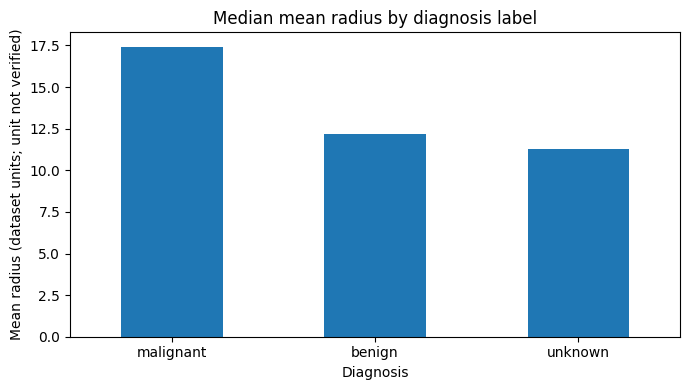

In [19]:
group_summary = clean.groupby(GROUP, dropna=False).agg(
    row_count=("sample_id", "size"),
    observed_radius_count=(FOCUS, "count"),
    mean_radius=(FOCUS, "mean"),
    median_radius=(FOCUS, "median"),
    mean_texture=("mean_texture", "mean"),
    mean_area=("mean_area", "mean"),
).sort_values("median_radius", ascending=False)
display(group_summary.round(4))

ax = group_summary["median_radius"].plot(kind="bar", figsize=(7, 4))
ax.set_title("Median mean radius by diagnosis label")
ax.set_ylabel("Mean radius (dataset units; unit not verified)")
ax.set_xlabel("Diagnosis")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## R. Final validation and export

In [20]:
# Validate the original snapshot, cleaned target, types, ranges, and scaling.
assert raw.equals(raw_snapshot), "The raw dataset was modified."
assert clean[FOCUS].notna().all(), "Clean data must not have missing mean_radius."
assert pd.api.types.is_numeric_dtype(clean[FOCUS])
assert clean[GROUP].notna().all()
assert clean[NUMERIC].notna().all().all(), "This dataset should have complete numeric fields after the focus-row filter."
assert (clean[NUMERIC] >= 0).all().all(), "Measurements must be non-negative; zero concavity is valid."
assert clean.duplicated(subset=raw.columns.tolist()).sum() == 0
assert np.isclose(minmax_scaled.min(), 0) and np.isclose(minmax_scaled.max(), 1)
assert np.isclose(z_scaled.mean(), 0) and np.isclose(z_scaled.std(ddof=1), 1)
assert np.allclose(scaled_features.min().to_numpy(), 0)
assert np.allclose(scaled_features.max().to_numpy(), 1)

# Audit rejected rows with an explicit reason.
duplicate_export = duplicate_review.copy()
duplicate_export["rejection_reason"] = "exact duplicate row (kept first occurrence)"
missing_export = missing_focus_review.copy()
missing_export["rejection_reason"] = "missing mean_radius"
rejected_rows = pd.concat([duplicate_export, missing_export], ignore_index=True, sort=False)

# Store scaling parameters for reproducibility.
scaling_parameters = pd.DataFrame({
    "feature": SCALE_COLUMNS,
    "minimum": clean[SCALE_COLUMNS].min().values,
    "maximum": clean[SCALE_COLUMNS].max().values,
    "mean": clean[SCALE_COLUMNS].mean().values,
    "sample_std": clean[SCALE_COLUMNS].std(ddof=1).values,
    "minmax_formula": ["(x - minimum) / (maximum - minimum)"] * len(SCALE_COLUMNS),
})

# Include both raw-unit cleaned measurements and a separate scaled copy.
scaled_export = clean.copy()
scaled_export.loc[:, SCALE_COLUMNS] = scaled_features

outputs = {
    "CLEANED_tissue_measurements.csv": clean,
    "SCALED_tissue_measurements.csv": scaled_export,
    "GROUP_SUMMARY_tissue.csv": group_summary.reset_index(),
    "REJECTED_ROWS_tissue.csv": rejected_rows,
    "SCALING_PARAMETERS_tissue.csv": scaling_parameters,
}
for filename, frame in outputs.items():
    frame.to_csv(filename, index=False)
    print(f"Saved {filename}: {frame.shape[0]} rows × {frame.shape[1]} columns")

# Round-trip check: exported cleaned file can be read and has expected key properties.
round_trip = pd.read_csv("CLEANED_tissue_measurements.csv")
assert round_trip.shape == clean.shape
assert round_trip[FOCUS].notna().all()
assert pd.api.types.is_numeric_dtype(round_trip[FOCUS])
assert round_trip[GROUP].notna().all()
print("\nFINAL SUMMARY")
print("Original rows:", len(raw))
print("Exact duplicate rows removed:", len(duplicate_review))
print("Unique rows removed for missing mean_radius:", len(missing_focus_review))
print("Clean rows:", len(clean))
print("Missing diagnosis labels retained as 'unknown':", int(clean[GROUP].eq("unknown").sum()))
print("All validation checks passed.")
assert len(clean) + len(rejected_rows) == len(raw)

Saved CLEANED_tissue_measurements.csv: 563 rows × 11 columns
Saved SCALED_tissue_measurements.csv: 563 rows × 11 columns
Saved GROUP_SUMMARY_tissue.csv: 3 rows × 7 columns
Saved REJECTED_ROWS_tissue.csv: 8 rows × 11 columns
Saved SCALING_PARAMETERS_tissue.csv: 8 rows × 6 columns

FINAL SUMMARY
Original rows: 571
Exact duplicate rows removed: 2
Unique rows removed for missing mean_radius: 6
Clean rows: 563
Missing diagnosis labels retained as 'unknown': 2
All validation checks passed.
